## setup

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 67

## data analysis

In [16]:
df = pd.read_csv("data/training_data_ht2026.csv")
df.head()

,hour_of_day,day_of_week,month,holiday,weekday,summertime,temp,dew,humidity,precip,snow,snowdepth,windspeed,cloudcover,visibility,increase_stock
0,5,5,1,0,0,0,-7.2,-15.0,53.68,0.0,0,0.0,16.3,31.6,16.0,low_bike_demand
1,21,4,1,0,1,0,-1.3,-12.8,40.97,0.0,0,0.0,23.9,85.7,16.0,low_bike_demand
2,21,3,8,0,1,1,26.9,21.8,73.39,0.0,0,0.0,0.0,81.1,16.0,low_bike_demand
3,1,6,1,0,0,0,3.1,-4.0,59.74,0.0,0,0.0,19.2,0.0,16.0,low_bike_demand
4,17,0,3,0,1,0,11.7,-11.4,18.71,0.0,0,0.0,10.5,44.6,16.0,low_bike_demand


- one row is one hour
- `increase_stock` is the predict label

In [17]:
print(df.shape) # (rows, columns)
print(df.isna().sum().sum(), df.duplicated().sum()) # missing values, duplicate rows
df.nunique() # unique values per feature

(1600, 16)
0 0


hour_of_day         24
day_of_week          7
month               12
holiday              2
weekday              2
summertime           2
temp               343
dew                313
humidity          1431
precip             126
snow                 1
snowdepth           41
windspeed          281
cloudcover         232
visibility          83
increase_stock       2
dtype: int64

snow has 1 unique value (0) so this feature can be dropped

In [18]:
df["high"] = (df.increase_stock == "high_bike_demand") * 1 # to make 0/1 instead of true/false
df.high.mean()

np.float64(0.18)

- `increase_stock` is text -> turn into 0/1 (1 = high demand)
- mean of `high` is % of hours with high demand

## Question (i)
Which are the numerical features and which are the categorical features?

Numerical: temp, dew, humidity, precip, snowdepth, windspeed, cloudover, visibility, snow 

Categorical: holiday, weekday, summertime, hour_of_day, day_of_week, month

*The time categoricals continuously start over e.g. each day starts with 0 although 0 paired with day_of_week=1 is not the same as 0 with day_of_week=2*

## Question (ii)
Is there a greater trend to need an increase in the availability of bicycles?
Study this question from various perspectives:
- Can any trend be seen comparing different hours, weeks, and months?
- Is there any difference between weekdays and holidays?
- Is there any trend depending on the weather? Rainy days, snowy days, etc

### Can any trend be seen comparing different hours, weeks, and months?

Text(0, 0.5, '% high demand')

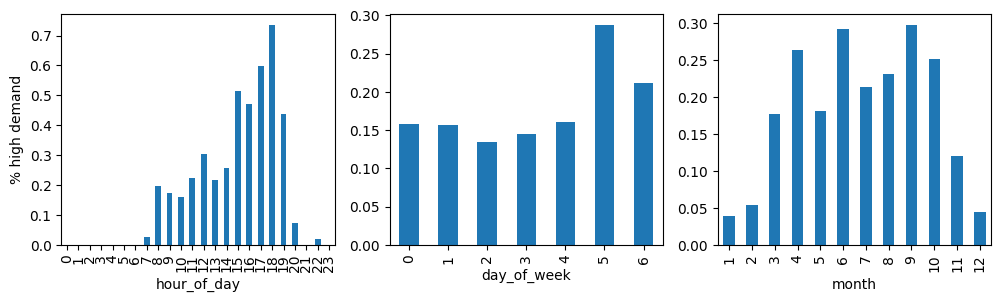

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
# SELECT hour_of_day, AVG(high) FROM df GROUP BY hour_of_day / day_of_week / month
df.groupby("hour_of_day").high.mean().plot.bar(ax=axes[0])
df.groupby("day_of_week").high.mean().plot.bar(ax=axes[1])
df.groupby("month").high.mean().plot.bar(ax=axes[2])
axes[0].set_ylabel("% high demand")

Hour has the strongest trend as high demand does not start until 07:00 and grows until it peaks at 18:00 and then quickly falls off at 20:00.

Month shows that the demand is low during winter (month 1, 2, 12), other than that it does not really show that one season has much more demand than another.

Day of week shows that saturday followed by sunday have the most demand (days 5 and 6, we can derive that these are saturday/sunday based on `weekday` in `df.head()`). During the weekdays the demand is roughly the same.

### Is there any difference between weekdays and holidays?

In [ ]:
# SELECT weekday, holiday, AVG(high), COUNT(*) FROM df GROUP BY weekday, holiday
df.groupby(["weekday", "holiday"]).high.agg(["mean", "size"])

mean  size
weekday holiday                
0       0        0.250000   464
1       0        0.150508  1083
        1        0.169811    53

All holidays on weekdays. Holiday does not look dissimilar to regular weekday (same high bike demand). 

Can be interepreted as most bike demand coming from riding bikes in late afternoon on weekends rather than commuting to work etc.; which the plots above support.

### Is there any trend depending on the weather? Rainy days, snowy days, etc.

Since there is no demand during the night, and the weather is likely colder, we filter out the nightly hours as we try and find some trends in the weather, leaving us with just the "daytime" hours (07:00-20:00).

In [ ]:
day = df[df.hour_of_day.between(7, 20)]
# SELECT high, AVG(temp), AVG(dew), ... FROM day GROUP BY high
day.groupby("high")[["temp", "dew", "humidity", "windspeed", "cloudcover", "visibility"]].mean().round(1)

,temp,dew,humidity,windspeed,cloudcover,visibility
high,,,,,,
0,13.8,6.1,62.5,14.5,67.5,15.0
1,21.9,10.6,51.3,14.7,61.2,15.9


And we also compare rain against no rain (mean `high_bike_demand` and count)

In [ ]:
# SELECT precip > 0 AS rain, AVG(high), COUNT(*) FROM day GROUP BY rain
day.groupby(day.precip > 0).high.agg(["mean", "size"]) # False = no rain

,mean,size
precip,,
False,0.334934,833
True,0.086957,92


Also the same with snowdepth

In [24]:
# SELECT snowdepth > 0 AS snow, AVG(high), COUNT(*) FROM day GROUP BY snow
day.groupby(day.snowdepth > 0).high.agg(["mean", "size"])

,mean,size
snowdepth,,
False,0.322472,890
True,0.000000,35


During days, 33% of hours without rain are high demand vs 9% on rainy days. And on days with snow (snowdepth > 0), there is never high demand for bikes. We can also see that the weather conditions that show a difference in mean value between high and low demand are temperature, dew, and to some extent humidity.

This concludes that the demand for bikes is much more likely to be high during warm and less humid days (but not necessarily sunny, just without rain). 